# Experimental design

Where should we observe a function if we want to learn its gradient at a
particular point? We'll choose a batch of four function-value observations,
optimizing their locations together to reduce uncertainty in that gradient.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import optax

from gpex import (
    FunctionalBlock,
    FunctionalQuery,
    GaussianProcess,
    ObservationDesign,
    ObservationDesignBlock,
    PreparedQuery,
    kernels,
    operators,
)

## Describe the existing observations

Our function has two input coordinates. We already have eight function-value
observations around the edge of a square, each with error variance `0.02`.
We use an RBF kernel with lengthscale `0.9`.

With the kernel parameters and error variances fixed, posterior uncertainty
depends on where and how we observe the function, but not on the readings.
An `ObservationDesign` describes just what we need for this calculation:
locations, operators, and error variances.

In [2]:
x_observed = jnp.array([
    [-2.0, -2.0], [-2.0, 0.0], [-2.0, 2.0],
    [0.0, -2.0],               [0.0, 2.0],
    [2.0, -2.0],  [2.0, 0.0],  [2.0, 2.0],
])
existing = ObservationDesign([
    ObservationDesignBlock(
        FunctionalBlock(x_observed, operators.Identity(), name="observed_values"),
        variance=0.02,
        max_size=8,
    )
])
gp = GaussianProcess(kernels.RBFKernel(variance=1.0, lengthscale=0.9))
conditioning = gp.prepare_conditioning(existing, jitter=1e-9)

## Choose the target

We want the gradient at `(0.25, -0.15)`: the function's rate of change in each
of the two coordinate directions. `Gradient()` gives us both components.

`PreparedQuery` caches the calculations for this fixed target and the existing
observations. We can reuse it while trying different locations for the new
observations.

In [3]:
x_target = jnp.array([[0.25, -0.15]])
gradient_query = FunctionalQuery([
    FunctionalBlock(x_target, operators.Gradient(), name="target_gradient")
])
prepared_gradient = PreparedQuery(conditioning, gradient_query)

## Score the whole batch

Our score is the sum of the two gradient variances after adding the four
proposed observations. Smaller values mean less uncertainty about the gradient.

We put all four locations in one `ObservationDesignBlock` and pass it to
`predict_variance_after`. This evaluates their combined information, accounting
for overlap between what they tell us. Scoring each observation separately
could favor several locations that provide much the same information.

The new observations have error variance `0.02`. We restrict their locations
to `(-2.5, 2.5)` in each coordinate by writing them as `2.5 * tanh(parameters)`.

In [4]:
domain_radius = 2.5


def gradient_loss(parameters):
    locations = domain_radius * jnp.tanh(parameters)
    proposed = ObservationDesignBlock(
        FunctionalBlock(locations, operators.Identity(), name="proposed_values"),
        variance=0.02,
        max_size=4,
    )
    variances = prepared_gradient.predict_variance_after(proposed)
    return jnp.sum(variances["target_gradient"])

## Optimize all four locations

`jax.value_and_grad` evaluates the score and differentiates it with respect
to the location parameters. These derivatives tell the optimizer how to move
the proposed observations. They are distinct from the gradient of the function
that we want to learn.

The helper below takes 180 Adam steps and records the score and locations
along the way. `jax.lax.scan` runs the steps in a loop compiled by `jax.jit`.

In [5]:
def optimize(loss, initial, steps=180):
    optimizer = optax.adam(learning_rate=0.05)

    @jax.jit
    def run(parameters):
        def step(carry, _):
            parameters, state = carry
            value, gradient = jax.value_and_grad(loss)(parameters)
            updates, state = optimizer.update(gradient, state, parameters)
            parameters = optax.apply_updates(parameters, updates)
            return (parameters, state), (value, parameters)

        (parameters, _), (history, trajectory) = jax.lax.scan(
            step, (parameters, optimizer.init(parameters)), None, length=steps
        )
        return parameters, history, trajectory

    return run(initial)

Let's start with four scattered locations. `arctanh` converts these locations
to the parameters used by the optimizer.

In [6]:
initial_locations = jnp.array([
    [-1.65, -0.85],
    [-0.70, 1.65],
    [1.70, 1.20],
    [1.55, -1.65],
])
initial_parameters = jnp.arctanh(initial_locations / domain_radius)
optimized_parameters, history, parameter_trajectory = optimize(
    gradient_loss, initial_parameters
)
optimized_locations = domain_radius * jnp.tanh(optimized_parameters)
location_trajectory = domain_radius * jnp.tanh(
    jnp.concatenate([initial_parameters[None, ...], parameter_trajectory])
)
gradient_scores = jnp.append(history, gradient_loss(optimized_parameters))

The left panel shows how the four proposed locations move. The right panel
shows the remaining gradient uncertainty for the whole batch at each step.

In [7]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})
BLUE, ORANGE, PURPLE = "#1F4E79", "#D97706", "#6D597A"

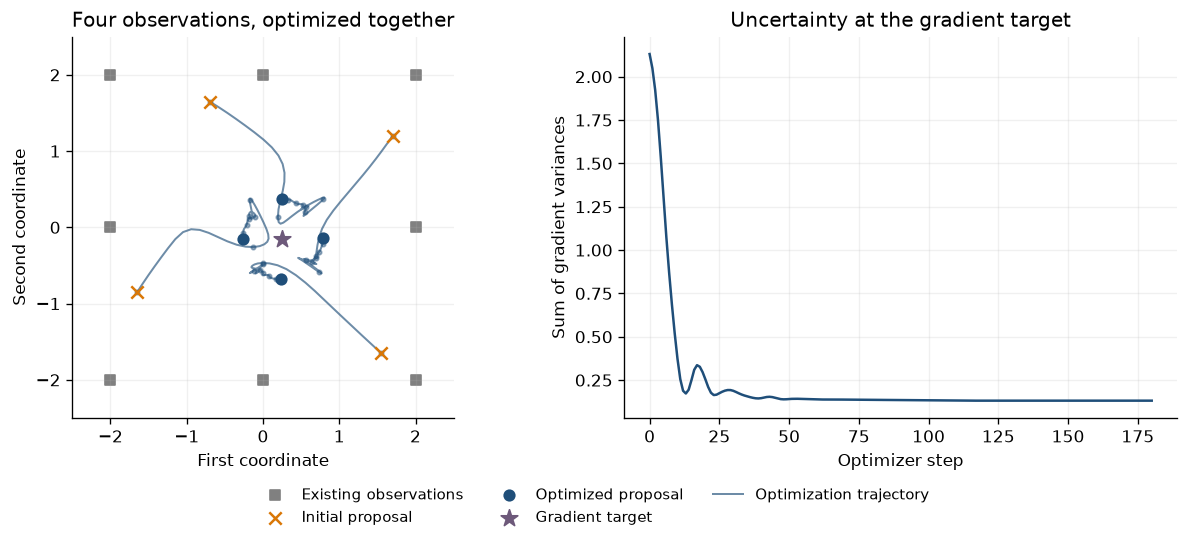

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
axes[0].scatter(
    x_observed[:, 0], x_observed[:, 1], color="0.5", marker="s",
    label="Existing observations",
)
axes[0].scatter(
    initial_locations[:, 0], initial_locations[:, 1], color=ORANGE,
    marker="x", s=55, label="Initial proposal", zorder=3,
)
axes[0].scatter(
    optimized_locations[:, 0], optimized_locations[:, 1], color=BLUE,
    s=40, label="Optimized proposal", zorder=3,
)
axes[0].scatter(
    x_target[:, 0], x_target[:, 1], color=PURPLE,
    marker="*", s=110, label="Gradient target", zorder=4,
)
for index in range(4):
    path = location_trajectory[:, index, :]
    axes[0].plot(
        path[:, 0], path[:, 1], color=BLUE, alpha=0.65, linewidth=1.2,
        label="Optimization trajectory" if index == 0 else None,
    )
    axes[0].scatter(path[::15, 0], path[::15, 1], color=BLUE, s=7, alpha=0.45)
axes[0].set(
    title="Four observations, optimized together",
    xlabel="First coordinate", ylabel="Second coordinate", aspect="equal",
    xlim=(-domain_radius, domain_radius), ylim=(-domain_radius, domain_radius),
)
axes[1].plot(gradient_scores, color=BLUE)
axes[1].set(
    title="Uncertainty at the gradient target",
    xlabel="Optimizer step", ylabel="Sum of gradient variances",
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="outside lower center", ncol=3,
    frameon=False, fontsize=9,
)
plt.show()

The proposed observations move to different sides of the target. Differences
between their values help us learn how the function changes in both coordinate
directions. This is a local optimization, so the final arrangement can depend
on the starting locations.

Reuse a `PreparedQuery` while optimizing proposals for the same GP, existing
observations, and target. Create a new one when any of those change.

Once the new readings arrive, [Sequential observations](sequential-streaming.ipynb)
shows how to update the posterior.